# Data Preprocessing

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)


Objetivo: Notebook de ejemplo para convertir épocas de señal cruda (salida de
`segmentation.py`) en features espectrales tabulares, listas para modelos
como XGBoost/Random Forest/SVM.

In [1]:
# Si falta alguna dependencia, descomenta:
# !pip install mne scipy pandas matplotlib --quiet

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import os


In [ ]:
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

DATA_DIR = project_root / "data/sleep-edfx/sleep-cassette" 

In [14]:
from src.data.loader import load_subject, find_subject_pairs
from src.data.segmentation import (
    extract_epochs,
    concatenate_datasets,
    class_distribution,
    INT_TO_CLASS,
    concatenate_datasets_by_split
)
from src.preprocessing.feature_engineering import extract_features, to_dataframe, FREQ_BANDS

## Cargar y segmentar

In [ ]:
PSG_PATH = "SC4001E0-PSG.edf"
HYPNO_PATH = "SC4001EC-Hypnogram.edf"

subject = load_subject(DATA_DIR / PSG_PATH, DATA_DIR / HYPNO_PATH)

epoch_ds = extract_epochs(
    subject.raw, subject.annotations,
    recording_id=subject.subject_id,
    channel_picks=["EEG Fpz-Cz"],   # agrega más canales aquí si quieres, p.ej. ["EEG Fpz-Cz", "EEG Pz-Oz"]
)

print("X (señal cruda) shape:", epoch_ds.X.shape, " (n_epochs, n_channels, n_samples)")
print("Canales:", epoch_ds.channel_names)

## Convertir a features espectrales

In [10]:
feat_ds = extract_features(epoch_ds)

print("X (features) shape:", feat_ds.X.shape, " (n_epochs, n_features)")
print(f"N° de features: {len(feat_ds.feature_names)}")
print("\nNombres de las features:")
for name in feat_ds.feature_names:
    print(" -", name)

X (features) shape: (2650, 14)  (n_epochs, n_features)
N° de features: 14

Nombres de las features:
 - EEG_Fpz-Cz__delta_power_abs
 - EEG_Fpz-Cz__delta_power_rel
 - EEG_Fpz-Cz__theta_power_abs
 - EEG_Fpz-Cz__theta_power_rel
 - EEG_Fpz-Cz__alpha_power_abs
 - EEG_Fpz-Cz__alpha_power_rel
 - EEG_Fpz-Cz__sigma_power_abs
 - EEG_Fpz-Cz__sigma_power_rel
 - EEG_Fpz-Cz__beta_power_abs
 - EEG_Fpz-Cz__beta_power_rel
 - EEG_Fpz-Cz__delta_alpha_ratio
 - EEG_Fpz-Cz__theta_alpha_ratio
 - EEG_Fpz-Cz__sef95
 - EEG_Fpz-Cz__spectral_entropy


## Ver un registro individual

In [5]:
i = 1050  # cambia el índice para ver otra época

print("Clase:", INT_TO_CLASS[feat_ds.y[i]])
print("recording_id:", feat_ds.recording_ids[i])
print("subject_code:", feat_ds.subject_codes[i])
print()
for name, value in zip(feat_ds.feature_names, feat_ds.X[i]):
    print(f"  {name:35s} = {value:.4f}")

Clase: N3
recording_id: SC4001E0
subject_code: 00

  EEG_Fpz-Cz__delta_power_abs         = 760.0042
  EEG_Fpz-Cz__delta_power_rel         = 0.9149
  EEG_Fpz-Cz__theta_power_abs         = 47.1583
  EEG_Fpz-Cz__theta_power_rel         = 0.0568
  EEG_Fpz-Cz__alpha_power_abs         = 12.5674
  EEG_Fpz-Cz__alpha_power_rel         = 0.0151
  EEG_Fpz-Cz__sigma_power_abs         = 3.4610
  EEG_Fpz-Cz__sigma_power_rel         = 0.0042
  EEG_Fpz-Cz__beta_power_abs          = 3.0979
  EEG_Fpz-Cz__beta_power_rel          = 0.0037
  EEG_Fpz-Cz__delta_alpha_ratio       = 60.4741
  EEG_Fpz-Cz__theta_alpha_ratio       = 3.7524
  EEG_Fpz-Cz__sef95                   = 4.7500
  EEG_Fpz-Cz__spectral_entropy        = 0.5179


## Convertir a DataFrame

In [11]:
df = to_dataframe(feat_ds)
print(df.shape)
df.head()

(2650, 17)


,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__theta_power_abs,EEG_Fpz-Cz__theta_power_rel,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__theta_alpha_ratio,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__spectral_entropy,y,recording_id,subject_code
0,671.110291,0.839784,93.338409,0.116798,9.160294,0.011463,3.006556,0.003762,10.273451,0.012856,73.262962,10.189456,5.00,0.473274,0,SC4001E0,00
1,396.884125,0.808501,43.067890,0.087734,13.562517,0.027628,7.554353,0.015389,29.577677,0.060253,29.263308,3.175509,26.25,0.599321,0,SC4001E0,00
2,519.377869,0.900573,21.867821,0.037918,13.469388,0.023355,4.506128,0.007813,16.238911,0.028157,38.559872,1.623520,9.50,0.460463,0,SC4001E0,00
3,186.942886,0.810687,18.589085,0.080612,13.446362,0.058311,2.128408,0.009230,7.254355,0.031459,13.902860,1.382462,12.25,0.601335,0,SC4001E0,00
4,182.196426,0.749786,35.283054,0.145199,11.765560,0.048418,1.892238,0.007787,6.364559,0.026192,15.485572,2.998842,11.50,0.638082,0,SC4001E0,00


## Comparar bandas espectrales promedio por clase

In [12]:
rel_cols = [c for c in df.columns if c.endswith("_power_rel")]

means_by_class = df.groupby("y")[rel_cols].mean()
means_by_class.index = [INT_TO_CLASS[i] for i in means_by_class.index]
means_by_class = means_by_class.round(3)
means_by_class

,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__theta_power_rel,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__sigma_power_rel,EEG_Fpz-Cz__beta_power_rel
W,0.836,0.089,0.022,0.009,0.035
N1,0.640,0.201,0.072,0.018,0.048
N2,0.816,0.110,0.031,0.022,0.020
N3,0.922,0.052,0.012,0.005,0.004
REM,0.657,0.214,0.062,0.015,0.035


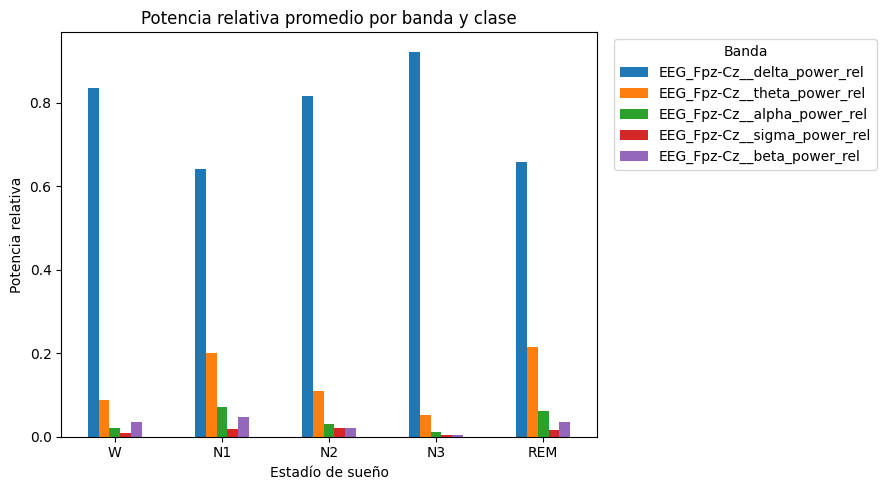

In [13]:
means_by_class.plot(kind="bar", figsize=(9, 5))
plt.title("Potencia relativa promedio por banda y clase")
plt.ylabel("Potencia relativa")
plt.xlabel("Estadío de sueño")
plt.xticks(rotation=0)
plt.legend(title="Banda", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Guardar las features en archivo csv

In [9]:
OUT_CSV = f"{feat_ds.recording_id}_features.csv"
df.to_csv(OUT_CSV, index=False)
print(f"Guardado: {OUT_CSV}")

# Alternativa .parquet (más compacto, preserva dtypes) -- requiere pyarrow o fastparquet instalado
# df.to_parquet(f"{feat_ds.recording_id}_features.parquet", index=False)

Guardado: SC4001E0_features.csv


## Procesar varios sujetos y juntar sus features

In [ ]:
DATA_DIR = project_root / f"data/sleep-edfx/sleep-cassette"  # carpeta con todos los .edf

pairs = find_subject_pairs(DATA_DIR)
print(f"{len(pairs)} par(es) encontrados")

all_features_dfs = []
for psg_path, hypno_path in pairs:
    subj = load_subject(psg_path, hypno_path)
    eds = extract_epochs(subj.raw, subj.annotations, recording_id=subj.subject_id,
                          channel_picks=["EEG Fpz-Cz"])
    fds = extract_features(eds)
    all_features_dfs.append(to_dataframe(fds))

if len(all_features_dfs) > 1:
    combined_df = pd.concat(all_features_dfs, ignore_index=True)
    print("Features combinadas:", combined_df.shape)
else:
    print("Solo hay un sujeto disponible en esta carpeta; nada que combinar todavía.")

In [20]:
combined_df.shape

(27597, 17)

In [21]:
combined_df.sample(10)

,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__theta_power_abs,EEG_Fpz-Cz__theta_power_rel,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__theta_alpha_ratio,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__spectral_entropy,y,recording_id,subject_code
6161,407.128021,0.932217,19.789942,0.045314,2.319360,0.005311,0.851838,0.001950,2.280822,0.005222,175.534607,8.532499,3.50,0.453933,0,SC4011E0,01
25948,30.860033,0.663137,5.565654,0.119598,3.324998,0.071449,1.153523,0.024788,6.184108,0.132887,9.281219,1.673882,31.75,0.549534,0,SC4042E0,04
11605,254.574615,0.955837,6.150818,0.023094,1.340177,0.005032,0.734097,0.002756,2.578228,0.009680,189.955917,4.589555,3.00,0.458469,0,SC4021E0,02
23454,148.484940,0.743038,21.602781,0.108103,12.675930,0.063432,12.579123,0.062948,12.584160,0.062973,11.713929,1.704237,12.75,0.560994,2,SC4041E0,04
18635,60.124619,0.697226,8.262510,0.095815,3.345655,0.038797,2.628618,0.030482,13.138906,0.152363,17.970957,2.469624,42.50,0.694437,0,SC4031E0,03
22010,287.272888,0.807159,33.824635,0.095038,11.876801,0.033371,5.812208,0.016331,15.457826,0.043432,24.187731,2.847958,50.00,0.493904,0,SC4032E0,03
25007,1020.216553,0.838315,133.909470,0.110034,16.555286,0.013604,7.560595,0.006213,22.312052,0.018334,61.624825,8.088624,6.25,0.553803,0,SC4042E0,04
16653,602.763428,0.924903,32.514366,0.049891,4.725378,0.007251,1.647308,0.002528,3.918502,0.006013,127.558784,6.880797,3.25,0.408628,0,SC4022E0,02
1050,760.004211,0.914941,47.158276,0.056772,12.567433,0.015129,3.461026,0.004167,3.097930,0.003729,60.474098,3.752419,4.75,0.517941,3,SC4001E0,00
15601,676.390015,0.960653,18.238075,0.025903,2.704851,0.003842,0.942355,0.001338,2.396755,0.003404,250.065536,6.742728,2.75,0.437110,0,SC4022E0,02


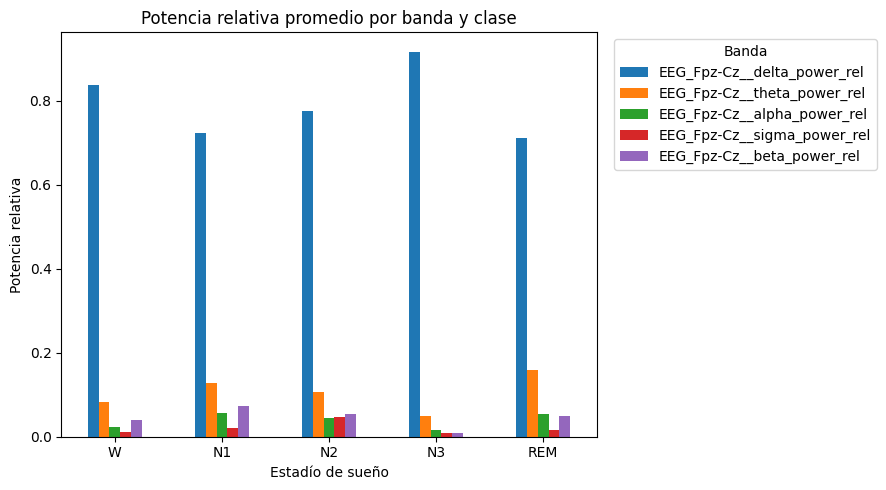

In [23]:
rel_cols = [c for c in combined_df.columns if c.endswith("_power_rel")]

means_by_class = combined_df.groupby("y")[rel_cols].mean()
means_by_class.index = [INT_TO_CLASS[i] for i in means_by_class.index]
means_by_class = means_by_class.round(3)
means_by_class

means_by_class.plot(kind="bar", figsize=(9, 5))
plt.title("Potencia relativa promedio por banda y clase")
plt.ylabel("Potencia relativa")
plt.xlabel("Estadío de sueño")
plt.xticks(rotation=0)
plt.legend(title="Banda", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

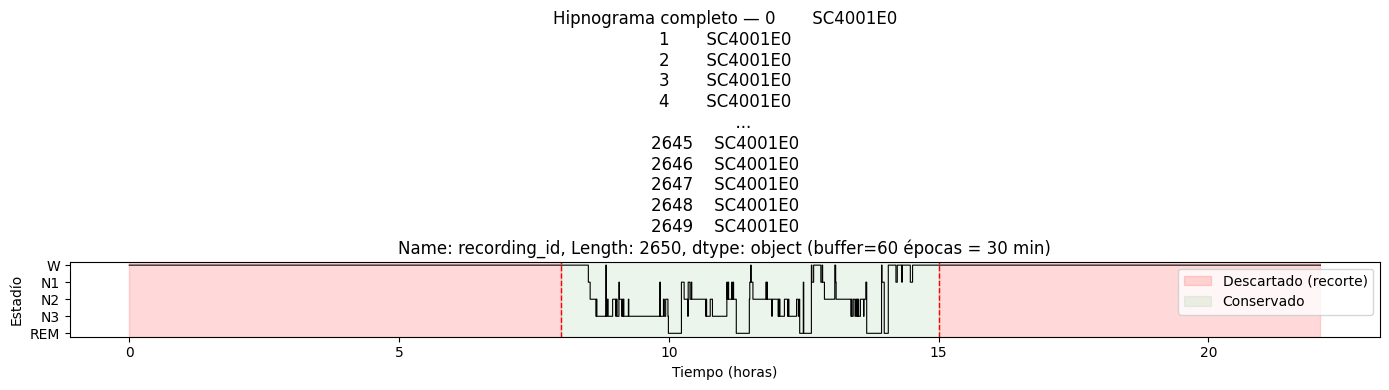

In [25]:
## Visualizar el hipnograma completo con las zonas de recorte

import numpy as np
import matplotlib.pyplot as plt

ds = df
BUFFER_EPOCHS = 60  # 60 * 30s = 30 minutos de buffer alrededor del sueño real

non_wake_idx = np.where(ds.y != 0)[0]
first_sleep = non_wake_idx.min()
last_sleep = non_wake_idx.max()
start = max(0, first_sleep - BUFFER_EPOCHS)
end = min(len(ds.y), last_sleep + BUFFER_EPOCHS + 1)

# Invertimos el eje para que W quede arriba y N3 abajo (convención estándar de hipnograma)
plot_order = {0: 4, 1: 3, 2: 2, 3: 1, 4: 0}  # W, N1, N2, N3, REM -> posición vertical
y_plot = np.array([plot_order[v] for v in ds.y])
tiempo_horas = np.arange(len(ds.y)) * 30 / 3600  # épocas de 30s -> horas

plt.figure(figsize=(14, 4))
plt.step(tiempo_horas, y_plot, where="post", color="black", linewidth=0.8)

plt.axvspan(0, tiempo_horas[start], color="red", alpha=0.15, label="Descartado (recorte)")
plt.axvspan(tiempo_horas[end-1], tiempo_horas[-1], color="red", alpha=0.15)
plt.axvspan(tiempo_horas[start], tiempo_horas[end-1], color="green", alpha=0.08, label="Conservado")
plt.axvline(tiempo_horas[start], color="red", linestyle="--", linewidth=1)
plt.axvline(tiempo_horas[end-1], color="red", linestyle="--", linewidth=1)

plt.yticks(list(plot_order.values()), [INT_TO_CLASS[k] for k in plot_order.keys()])
plt.xlabel("Tiempo (horas)")
plt.ylabel("Estadío")
plt.title(f"Hipnograma completo — {ds.recording_id} (buffer={BUFFER_EPOCHS} épocas = 30 min)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()